# Calidad del aire en Bogotá (RMCAB): inventario y limpieza
**Proyecto 2 – Información Systems (cuarto periodo)**

Flujo: 1) conectar Drive → 2) inventario → 3) limpieza → 4) cobertura (≥75 %) → 5) exportar + hashes de integridad.

Antes de correr: sube la carpeta `data` a Drive en `proyecto_aire/data`.

## 1. Conectar Drive y configurar rutas

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd, numpy as np, glob, os, re, hashlib, zipfile
import matplotlib.pyplot as plt
from google.colab import files

subido = files.upload()          # elige data.zip
with zipfile.ZipFile(list(subido)[0]) as z:
    z.extractall('/content/data')

RUTA   = '/content/data'
SALIDA = '/content/salida'
os.makedirs(SALIDA, exist_ok=True)

archivos = sorted(glob.glob(os.path.join(RUTA, '**', '*.csv'), recursive=True))
print(len(archivos), 'archivos encontrados')   # esperado: 54

Saving Dataset Air Quality Bogota.zip to Dataset Air Quality Bogota.zip
54 archivos encontrados


## 2. Funciones auxiliares

In [ ]:
def leer(f):
    for enc in ('utf-8', 'latin-1'):
        try:
            df = pd.read_csv(f, encoding=enc)
            if df.shape[1] == 1:                       # separador ';'
                df = pd.read_csv(f, sep=';', encoding=enc)
            return df
        except UnicodeDecodeError:
            continue
    raise ValueError(f'No se pudo leer {f}')

def estacion_contaminante(f):
    base = os.path.basename(f)[:-4]
    est, cont = base.rsplit('_', 1)
    return est.strip(), cont.upper()

def detectar(df):
    cols = list(df.columns)
    fecha = next((c for c in cols if re.search(r'date|fecha|time|hora', str(c), re.I)), cols[0])
    otras = [c for c in cols if c != fecha]
    valor = next((c for c in otras if re.search(r'pm', str(c), re.I)), None)
    if valor is None:
        for c in otras:
            if pd.to_numeric(df[c].astype(str).str.replace(',', '.'), errors='coerce').notna().mean() > 0.5:
                valor = c
                break
    return fecha, valor

def a_numero(s):
    return pd.to_numeric(s.astype(str).str.replace(',', '.', regex=False), errors='coerce')

## 3. Mirar la estructura de un archivo

In [ ]:
df0 = leer(archivos[0])
print(os.path.basename(archivos[0]))
print(df0.dtypes)
df0.head()

Base Aérea_pm10.csv
Estacion          object
Fecha inicial     object
Fecha final      float64
PM10             float64
dtype: object


,Estacion,Fecha inicial,Fecha final,PM10
0,BASE AÉREA,2004-10-22,NaN,4.442857
1,BASE AÉREA,2004-10-21,NaN,4.162083
2,BASE AÉREA,2004-10-20,NaN,4.010833
3,BASE AÉREA,2004-10-19,NaN,3.865000
4,BASE AÉREA,2004-10-18,NaN,15.246087


## 4. Inventario de los 54 archivos

In [ ]:
filas = []
for f in archivos:
    est, cont = estacion_contaminante(f)
    df = leer(f)
    fc, vc = detectar(df)
    if vc is None:
        print('⚠️ sin columna de valores:', os.path.basename(f))
        continue
    fechas = pd.to_datetime(df[fc], errors='coerce')
    vals = a_numero(df[vc])
    filas.append({'estacion': est, 'contaminante': cont, 'filas': len(df),
                  'col_fecha': fc, 'col_valor': vc,
                  'fecha_min': fechas.min(), 'fecha_max': fechas.max(),
                  'pct_faltante': round(vals.isna().mean() * 100, 1)})
inventario = pd.DataFrame(filas)
inventario.to_csv(os.path.join(SALIDA, 'inventario.csv'), index=False)
inventario

,estacion,contaminante,filas,col_fecha,col_valor,fecha_min,fecha_max,pct_faltante
0,Base Aérea,PM10,327,Fecha inicial,PM10,2003-12-01,2004-10-22,0.0
1,Base Aérea,PM25,2088,Fecha inicial,PM2.5,2013-04-02,2021-07-27,0.0
2,Bolivia,PM10,481,Fecha inicial,PM10,2012-03-16,2021-02-28,0.0
3,Bolivia,PM25,133,Fecha inicial,PM2.5,2020-10-16,2021-02-28,0.0
4,Bosa,PM10,128,Fecha inicial,PM10,2020-10-01,2021-02-28,0.0
5,Bosa,PM25,128,Fecha inicial,PM2.5,2020-10-01,2021-02-28,0.0
6,Carvajal,PM10,3909,Fecha inicial,PM10,2010-01-01,2021-02-28,0.0
7,Carvajal,PM25,2413,Fecha inicial,PM2.5,2014-01-01,2021-02-28,0.0
8,Cañaveralejo,PM10,2247,Fecha inicial,PM10,2014-06-26,2021-07-27,0.0
9,Cañaveralejo,PM25,412,Fecha inicial,PM2.5,2020-01-29,2021-07-27,0.0


## 5. Limpieza → tabla única (estación, contaminante, fecha, valor)

In [ ]:
bitacora, tablas = [], []
for f in archivos:
    est, cont = estacion_contaminante(f)
    df = leer(f)
    fc, vc = detectar(df)
    if vc is None:
        continue
    n0 = len(df)
    fecha = pd.to_datetime(df[fc], errors='coerce')
    orig = df[vc]
    valor = a_numero(orig)

    no_num = int((valor.isna() & orig.notna()).sum())     # texto que no es número
    fecha_mala = int(fecha.isna().sum())
    t = pd.DataFrame({'estacion': est, 'contaminante': cont, 'fecha': fecha, 'valor': valor})
    t = t.dropna(subset=['fecha'])
    neg = int((t['valor'] < 0).sum())
    t.loc[t['valor'] < 0, 'valor'] = np.nan                # negativos imposibles → faltante
    dup = int(t.duplicated(subset=['fecha']).sum())
    t = t.drop_duplicates(subset=['fecha'], keep='first')

    bitacora.append({'estacion': est, 'contaminante': cont, 'filas_iniciales': n0,
                     'fechas_invalidas': fecha_mala, 'valores_no_numericos': no_num,
                     'negativos_a_nan': neg, 'duplicados_eliminados': dup,
                     'filas_finales': len(t), 'faltantes_finales': int(t['valor'].isna().sum())})
    tablas.append(t)

datos = pd.concat(tablas, ignore_index=True)
bitacora = pd.DataFrame(bitacora)
bitacora.to_csv(os.path.join(SALIDA, 'bitacora_limpieza.csv'), index=False)
print(datos.shape)
bitacora

(98432, 4)


,estacion,contaminante,filas_iniciales,fechas_invalidas,valores_no_numericos,negativos_a_nan,duplicados_eliminados,filas_finales,faltantes_finales
0,Base Aérea,PM10,327,0,0,0,0,327,0
1,Base Aérea,PM25,2088,0,0,0,0,2088,0
2,Bolivia,PM10,481,0,0,0,0,481,0
3,Bolivia,PM25,133,0,0,0,0,133,0
4,Bosa,PM10,128,0,0,0,0,128,0
5,Bosa,PM25,128,0,0,0,0,128,0
6,Carvajal,PM10,3909,0,0,0,0,3909,0
7,Carvajal,PM25,2413,0,0,0,0,2413,0
8,Cañaveralejo,PM10,2247,0,0,0,0,2247,0
9,Cañaveralejo,PM25,412,0,0,0,0,412,0


## 6. Cobertura por estación/año (regla del 75 %)

In [ ]:
res = []
for (est, cont), g in datos.groupby(['estacion', 'contaminante']):
    g = g.sort_values('fecha')
    paso_h = g['fecha'].diff().dt.total_seconds().median() / 3600
    if not paso_h or np.isnan(paso_h) or paso_h <= 0:
        paso_h = 1
    esperado = (365 * 24) / paso_h
    for anio, ga in g.groupby(g['fecha'].dt.year):
        validos = int(ga['valor'].notna().sum())
        cob = validos / esperado
        res.append({'estacion': est, 'contaminante': cont, 'anio': anio,
                    'validos': validos, 'cobertura_%': round(cob * 100, 1),
                    'cumple_75': cob >= 0.75})
cobertura = pd.DataFrame(res)
cobertura.to_csv(os.path.join(SALIDA, 'cobertura.csv'), index=False)
print(cobertura['cumple_75'].value_counts())
cobertura.sort_values('cobertura_%', ascending=False).head(20)

cumple_75
True     244
False    114
Name: count, dtype: int64


,estacion,contaminante,anio,validos,cobertura_%,cumple_75
301,Transitoria,PM25,2020,185,253.4,True
311,Tunal,PM10,2020,366,100.3,True
218,Movil 7ma,PM25,2020,366,100.3,True
140,Kennedy,PM10,2020,366,100.3,True
128,Guaymaral,PM25,2020,366,100.3,True
148,Kennedy,PM25,2020,366,100.3,True
250,Puente Aranda,PM25,2020,366,100.3,True
65,Centro de alto rendimiento,PM25,2016,366,100.3,True
318,Tunal,PM25,2020,366,100.3,True
212,MinAmbiente,PM25,2020,366,100.3,True


## 7. Exportar datos limpios

In [ ]:
ok = cobertura[cobertura['cumple_75']][['estacion', 'contaminante', 'anio']]
datos['anio'] = datos['fecha'].dt.year
limpio = datos.merge(ok, on=['estacion', 'contaminante', 'anio'], how='inner')
limpio.to_csv(os.path.join(SALIDA, 'calidad_aire_limpio.csv'), index=False)
print('Filas totales:', len(datos), '| filas que cumplen 75 %:', len(limpio))

Filas totales: 98432 | filas que cumplen 75 %: 83430


## 8. Revisión rápida (gráfico de control)

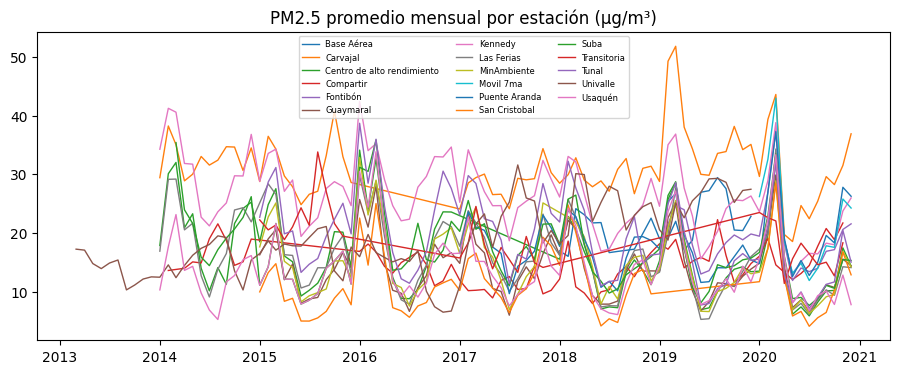

In [ ]:
g = limpio[limpio['contaminante'] == 'PM25'].copy()
g['mes'] = g['fecha'].dt.to_period('M').dt.to_timestamp()
g = g.groupby(['estacion', 'mes'])['valor'].mean().reset_index()
fig, ax = plt.subplots(figsize=(11, 4))
for est, ge in g.groupby('estacion'):
    ax.plot(ge['mes'], ge['valor'], label=est, linewidth=1)
ax.set_title('PM2.5 promedio mensual por estación (µg/m³)')
ax.legend(fontsize=6, ncol=3)
plt.show()

## 9. Integridad: huellas SHA-256 de los originales

In [ ]:
def sha256(f):
    h = hashlib.sha256()
    with open(f, 'rb') as fh:
        for bloque in iter(lambda: fh.read(65536), b''):
            h.update(bloque)
    return h.hexdigest()

manifiesto = pd.DataFrame({'archivo': [os.path.basename(f) for f in archivos],
                           'sha256': [sha256(f) for f in archivos]})
manifiesto.to_csv(os.path.join(SALIDA, 'manifiesto_hashes.csv'), index=False)
manifiesto.head()

,archivo,sha256
0,Base Aérea_pm10.csv,ddc3e870eafeed3c39878a0bcac5e808866a40ab9624c3...
1,Base Aérea_pm25.csv,62404f72dea25978e2d973b71d166da61759c759e098d4...
2,Bolivia_pm10.csv,34ecd712e3b28a37bab4743a2712deaab216edef2a25f2...
3,Bolivia_pm25.csv,209a9068b6bf351ce62c5a7d9b447bce7ce610fc1c08d9...
4,Bosa_pm10.csv,e1e2dc246a0a75cfb78680af43a761b4d2ac3f7b95d737...


In [ ]:
import shutil
shutil.make_archive('/content/resultados', 'zip', SALIDA)
files.download('/content/resultados.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
cobertura[cobertura.cumple_75].groupby(['estacion','contaminante']).anio.agg(['min','max','count'])

min   max  count
estacion                   contaminante                   
Base Aérea                 PM10          2004  2004      1
                           PM25          2018  2019      2
Carvajal                   PM10          2010  2020     11
                           PM25          2014  2020      6
Cañaveralejo               PM10          2015  2020      5
Centro de alto rendimiento PM10          2010  2020     11
                           PM25          2014  2020      6
Compartir                  PM10          2016  2020      5
                           PM25          2014  2020      6
ERA-Obrero                 PM10          2016  2020      4
Fontibón                   PM10          2019  2020      2
                           PM25          2019  2020      2
Guaymaral                  PM10          2010  2020     10
                           PM25          2015  2020      6
Kennedy                    PM10          2010  2020     11
                           PM25          2014  2020      7
La Ermita                  PM10          2014  2020      7
La Flora                   PM10          2011  2020      8
Las Ferias                 PM10          2010  2020     11
                           PM25          2014  2020      7
MinAmbiente                PM10          2012  2020      9
                           PM25          2015  2020      6
Movil 7ma                  PM10          2020  2020      1
                           PM25          2020  2020      1
Pance                      PM10          2014  2020      7
Puente Aranda              PM10          2010  2020     11
                           PM25          2017  2020      4
San Cristobal              PM10          2011  2020     10
                           PM25          2015  2020      5
Suba                       PM10          2010  2020     11
                           PM25          2014  2020      7
Transitoria                PM10          2016  2017      2
                           PM25          2015  2020      3
Tunal                      PM10          2010  2020     10
                           PM25          2015  2020      6
Univalle                   PM25          2013  2019      7
Usaquén                    PM10          2010  2019      9
                           PM25          2014  2020      7